In [2]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator, NullFormatter

NPZ_PATH = "/Users/tanya/Downloads/eda_arrays.npz"

TRK_FEATURES = ['elemtype', 'pt', 'eta', 'sin_phi', 'cos_phi', 'p', 'chi2', 'ndf',
                'dEdx', 'dEdxError', 'radiusOfInnermostHit', 'tanLambda', 'D0',
                'omega', 'Z0', 'time']
CL_FEATURES = ['elemtype', 'et', 'eta', 'sin_phi', 'cos_phi', 'energy',
               'position.x', 'position.y', 'position.z', 'iTheta',
               'energy_ecal', 'energy_hcal', 'energy_other', 'num_hits',
               'sigma_x', 'sigma_y', 'sigma_z']
CLASS_NAMES = ["none", "chhad", "nhad", "gamma", "ele", "mu"]

# one fixed color per class, so a class looks the same in every plot
CLASS_COLORS = {
    0: "#8a8a8a",  # none
    1: "#2a78d6",  # chhad
    2: "#4a3aa7",  # nhad
    3: "#eda100",  # gamma
    4: "#eb6834",  # ele
    5: "#1baf7a",  # mu
}

plt.rcParams.update({
    "font.size": 12,
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
    "axes.labelsize": 11,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "legend.fontsize": 12,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": "#e5e5e5",
    "grid.linewidth": 0.8,
    "axes.axisbelow": True,
    "figure.dpi": 100,
})


def plot_feature_grid(X, mask, features, idx, classes, units, logx=(), ncols=4, title=None):
    """One step histogram per feature, overlaying the given classes with shared bins.
    Features in `logx` are drawn on log-spaced bins (heavy-tailed, strictly positive)."""
    nrows = int(np.ceil(len(features) / ncols))
    height = 3.6 * nrows + 0.8  # +0.8 inch header for title and legend
    fig, axes = plt.subplots(nrows, ncols, figsize=(4.5 * ncols, height))
    axes = axes.ravel()
    for ax, i, feat_name in zip(axes, idx, features):
        per_class = {}
        for k in classes:
            vals = X[mask & (cls_all == k), i]
            vals = vals[np.isfinite(vals)]
            if feat_name in logx:
                vals = vals[vals > 0]
            if len(vals) > 0:
                per_class[k] = vals
        if not per_class:
            ax.axis("off")
            continue
        combined = np.concatenate(list(per_class.values()))
        lo, hi = np.percentile(combined, [0.5, 99.5])
        if lo == hi:  # avoid "identical low and high xlims" warning
            lo, hi = lo - 1, hi + 1
        if feat_name in logx:
            bins = np.geomspace(lo, hi, 50)
            ax.set_xscale("log")
        elif np.all(combined == np.round(combined)) and hi - lo < 100:
            bins = np.arange(lo - 0.5, hi + 1.5)  # integer feature: one bin per value
            lo, hi = bins[0], bins[-1]
        else:
            bins = np.linspace(lo, hi, 50)
            ax.xaxis.set_major_locator(MaxNLocator(5))
        for k, vals in per_class.items():
            ax.hist(vals, bins=bins, histtype="step", density=True,
                    linewidth=1.8, color=CLASS_COLORS[k], label=CLASS_NAMES[k])
        ax.set_xlim(lo, hi)
        ax.set_yscale("log")
        ylo, yhi = ax.get_ylim()
        if yhi / ylo > 10:  # minor labels only needed when the axis spans under one decade
            ax.yaxis.set_minor_formatter(NullFormatter())
        unit = units.get(feat_name, "")
        ax.set_title(feat_name)
        ax.set_xlabel(f"{feat_name} [{unit}]" if unit else feat_name)
    for ax in axes[0::ncols]:
        ax.set_ylabel("density")
    for ax in axes[len(features):]:
        ax.axis("off")
    if title:
        fig.suptitle(title, y=1 - 0.15 / height, va="top", fontsize=15, fontweight="bold")
    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="upper center", ncol=len(classes), frameon=False,
               bbox_to_anchor=(0.5, 1 - 0.45 / height))
    fig.tight_layout(rect=(0, 0, 1, 1 - 0.8 / height))
    return fig

In [8]:
data = np.load(NPZ_PATH)
X_all, ytarget_all, ycand_all = data["X"], data["ytarget"], data["ycand"]

cls_all = ytarget_all[:, 0].astype(int)
cand_cls_all = ycand_all[:, 0].astype(int)
elemtype = X_all[:, 0]
is_track = elemtype == 1
is_cluster = elemtype == 2

print("X_all:", X_all.shape)
print("elemtype counts:", np.unique(elemtype, return_counts=True))
print("target class counts:", np.bincount(cls_all, minlength=6))
print("baseline (ycand) class counts:", np.bincount(cand_cls_all, minlength=6))

X_all: (2298302, 17)
elemtype counts: (array([1., 2.], dtype=float32), array([ 208411, 2089891]))
target class counts: [929996 153838 625120 585896   2346   1106]
baseline (ycand) class counts: [ 162932  133424 1250191  731007   19439    1309]


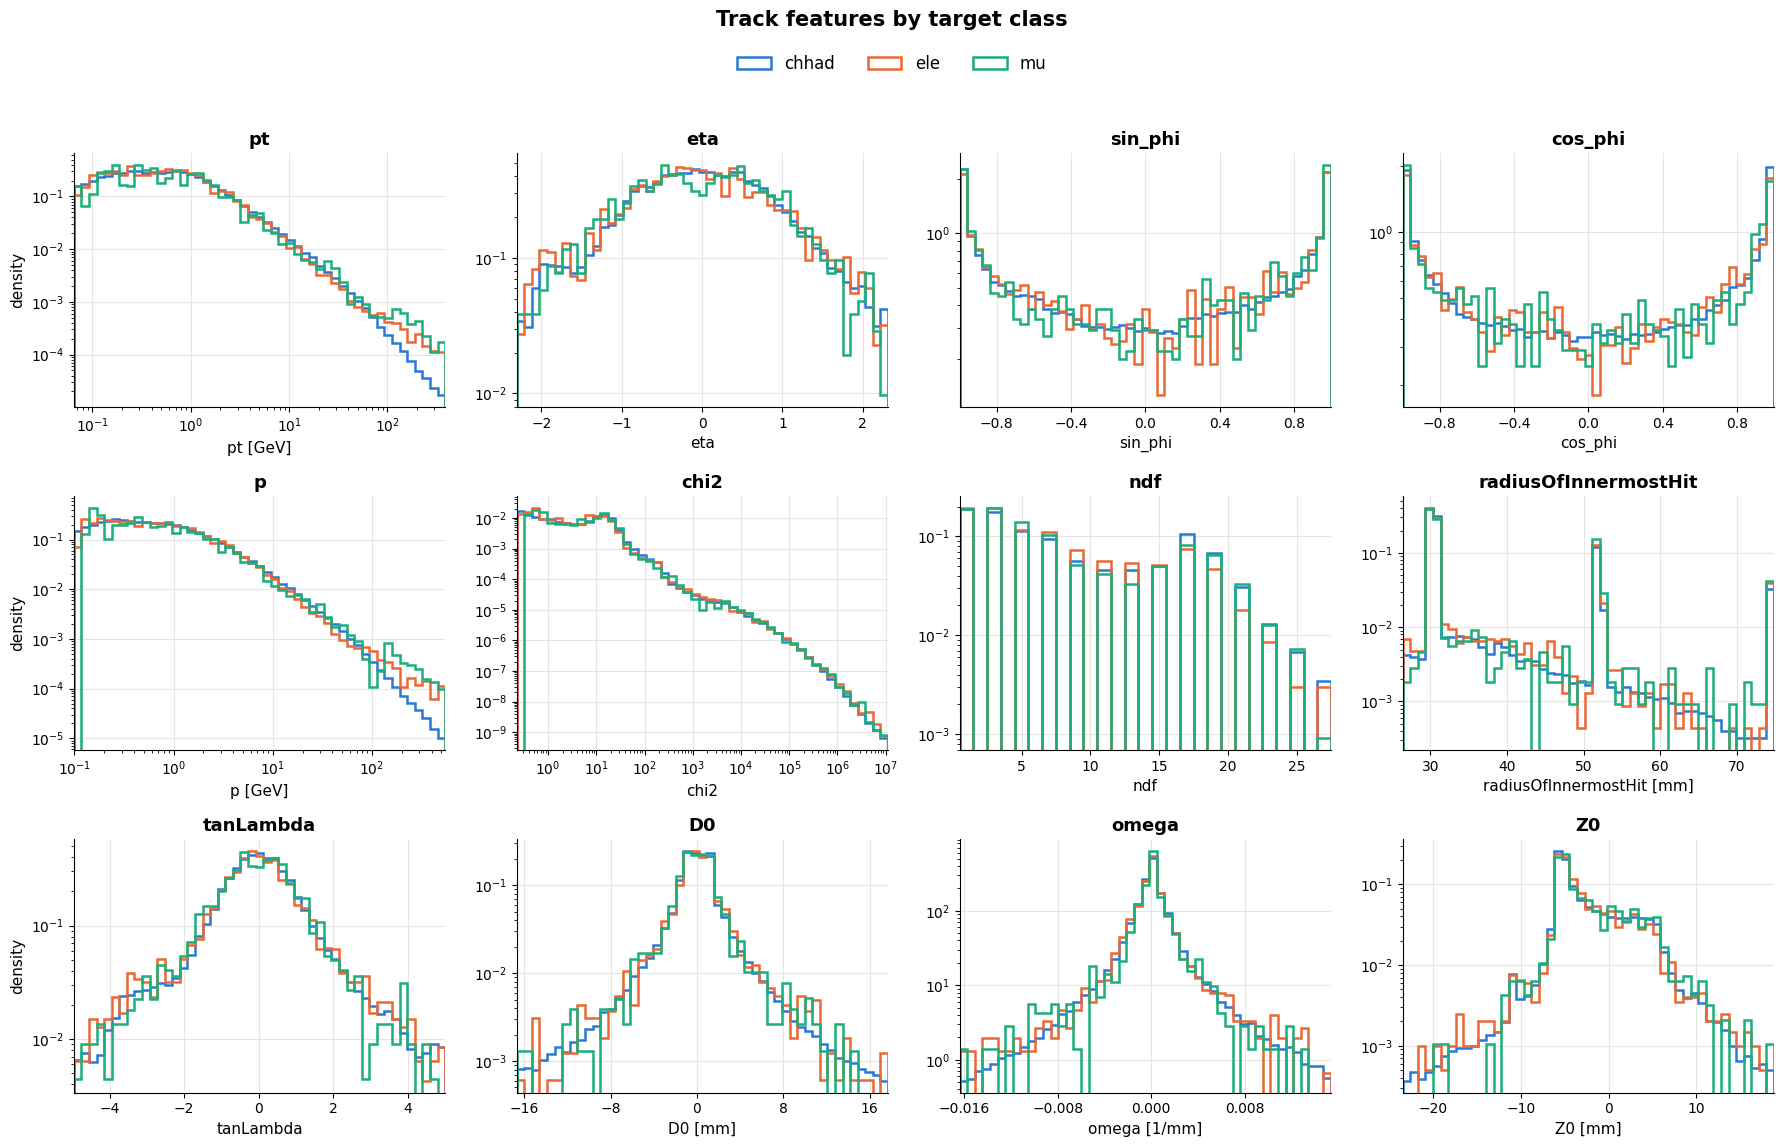

In [9]:
TRK_UNITS = {
    "pt": "GeV", "p": "GeV", "radiusOfInnermostHit": "mm",
    "D0": "mm", "omega": "1/mm", "Z0": "mm",
}

# drop elemtype (constant) and dead features (all 0 or -1)
TRK_FEATURES_LIVE = [f for f in TRK_FEATURES if f not in ("elemtype", "dEdx", "dEdxError", "time")]
trk_live_idx = [TRK_FEATURES.index(f) for f in TRK_FEATURES_LIVE]

# log-x only for strictly positive, wide-range features (omega is signed, so it stays linear)
plot_feature_grid(X_all, is_track, TRK_FEATURES_LIVE, trk_live_idx, classes=[1, 4, 5],
                  units=TRK_UNITS, logx=("pt", "p", "chi2"),
                  title="Track features by target class")
plt.show()

elemtype 1 = track , elemtype 2 = cluster

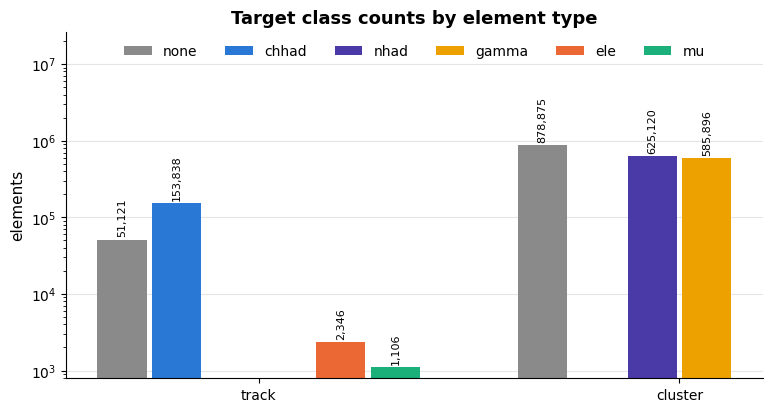

In [10]:
# element counts per target class, split by element type (log scale: classes span 3 orders of magnitude)
counts = np.array([[np.sum(is_track & (cls_all == k)), np.sum(is_cluster & (cls_all == k))]
                   for k in range(6)])

fig, ax = plt.subplots(figsize=(9, 4.5))
x = np.arange(2)
width = 0.13
for k in range(6):
    xpos = x + (k - 2.5) * width
    nonzero = counts[k] > 0
    bars = ax.bar(xpos[nonzero], counts[k][nonzero], width * 0.9,
                  color=CLASS_COLORS[k], label=CLASS_NAMES[k])
    ax.bar_label(bars, labels=[f"{c:,}" for c in counts[k][nonzero]],
                 fontsize=8, padding=2, rotation=90)
ax.set_xticks(x)
ax.set_xticklabels(["track", "cluster"])
ax.set_yscale("log")
ax.set_ylim(top=counts.max() * 30)
ax.set_ylabel("elements")
ax.set_title("Target class counts by element type")
ax.grid(axis="x", visible=False)
ax.legend(ncol=6, loc="upper center", frameon=False, fontsize=10)
plt.show()

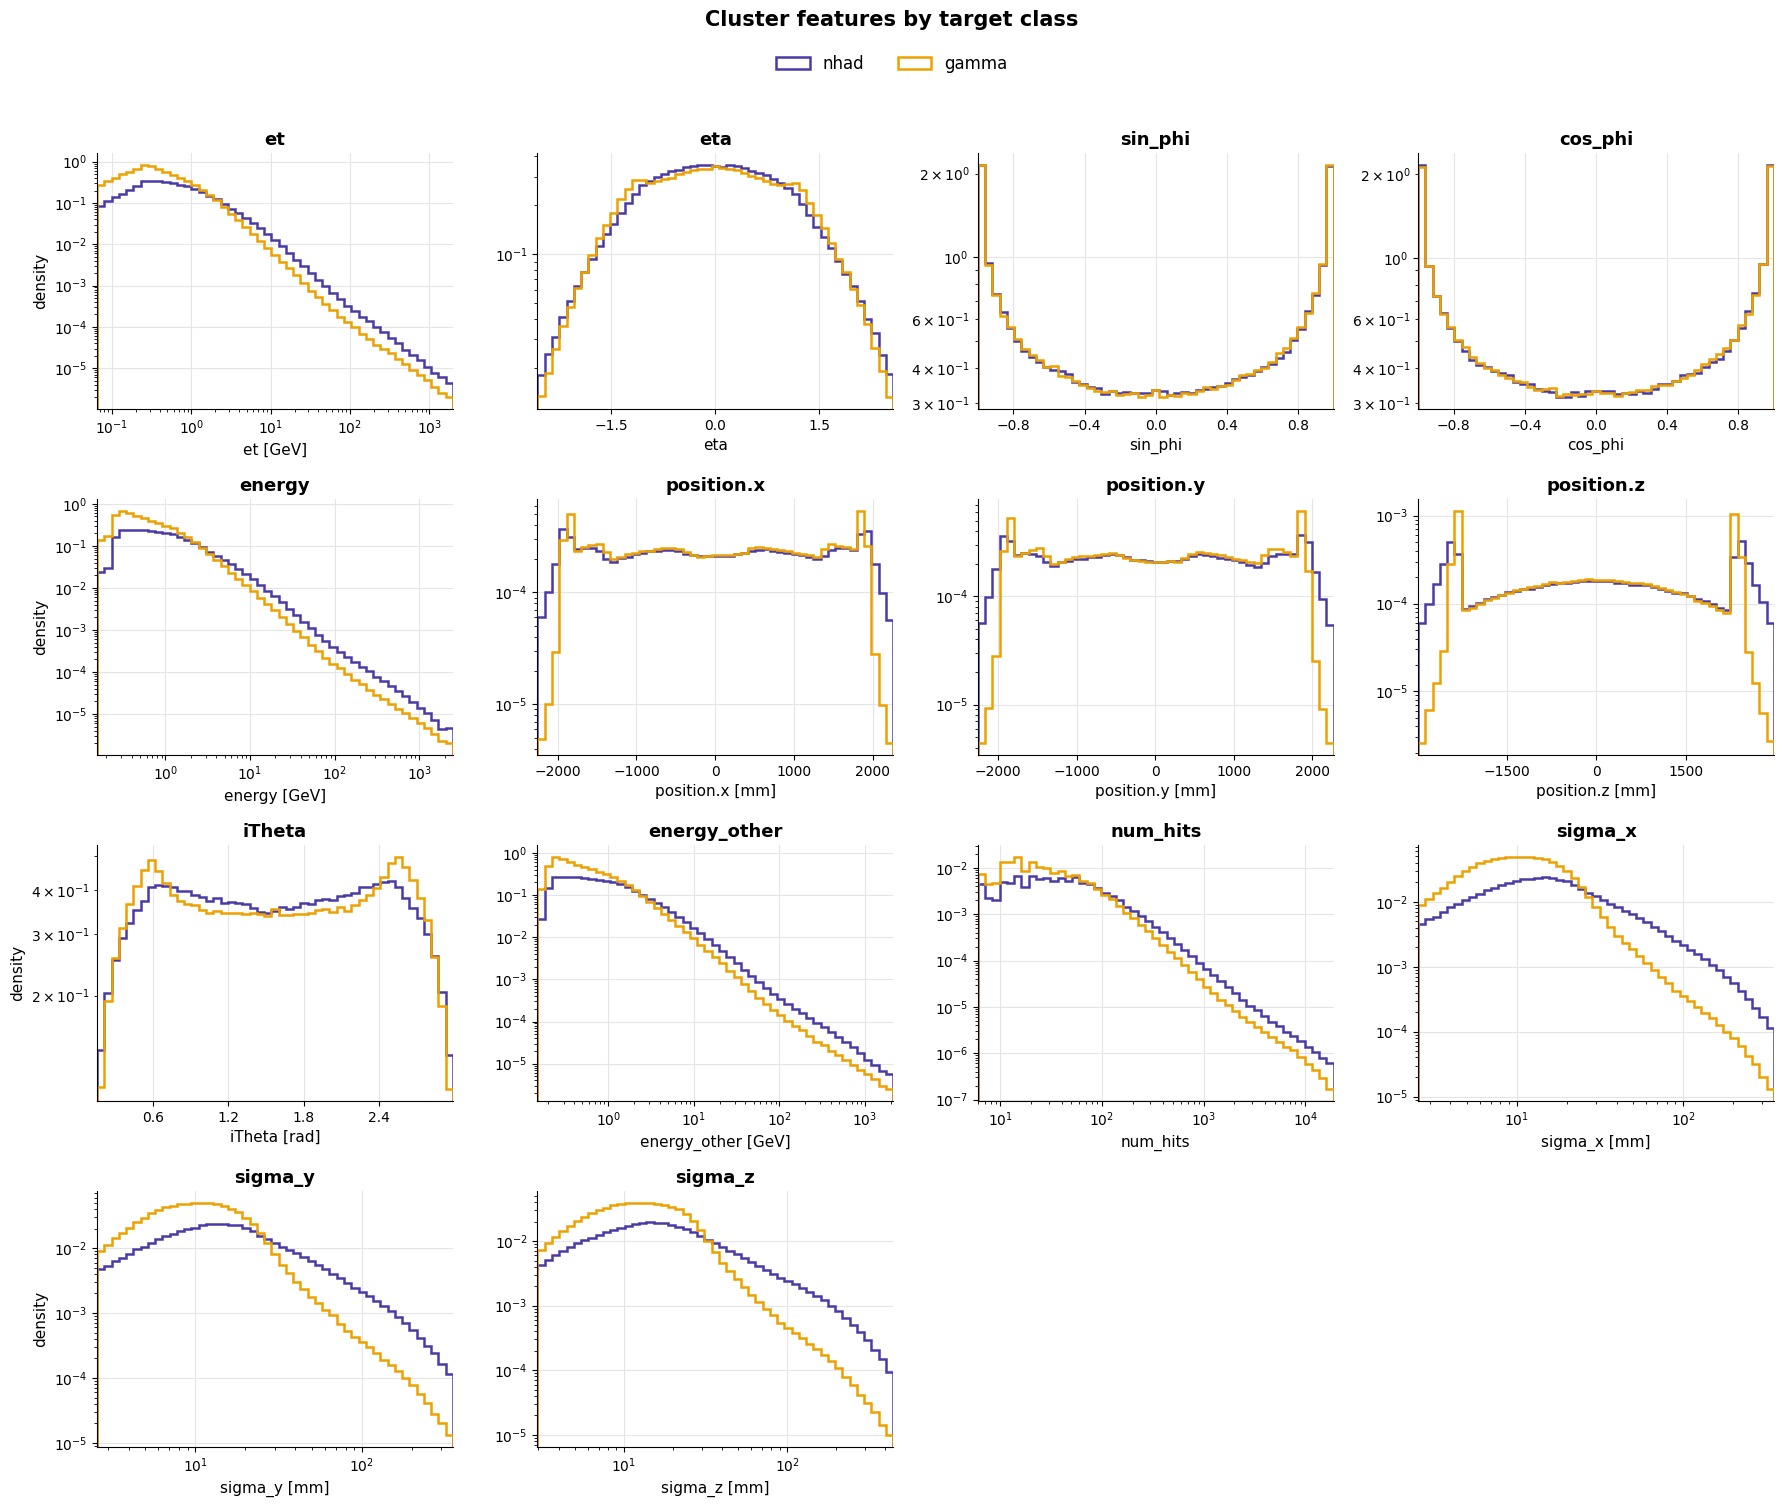

In [11]:
# Cluster feature distributions
# Clusters only have none (0), nhad (2) and gamma (3) targets; plot the physical classes
CL_UNITS = {
    "et": "GeV", "energy": "GeV", "energy_other": "GeV",
    "position.x": "mm", "position.y": "mm", "position.z": "mm", "iTheta": "rad",
    "sigma_x": "mm", "sigma_y": "mm", "sigma_z": "mm",
}

# drop elemtype (constant) and dead features (all 0)
CL_FEATURES_LIVE = [f for f in CL_FEATURES if f not in ("elemtype", "energy_ecal", "energy_hcal")]
cl_live_idx = [CL_FEATURES.index(f) for f in CL_FEATURES_LIVE]

# strictly positive with huge dynamic range -> log-x; position.* straddle zero, angles are bounded -> linear
CL_LOGX = ("et", "energy", "energy_other", "num_hits", "sigma_x", "sigma_y", "sigma_z")

plot_feature_grid(X_all, is_cluster, CL_FEATURES_LIVE, cl_live_idx, classes=[2, 3],
                  units=CL_UNITS, logx=CL_LOGX,
                  title="Cluster features by target class")
plt.show()

In [12]:
for i, name in enumerate(TRK_FEATURES):
    vals = X_all[is_track, i]
    vals = vals[np.isfinite(vals)]
    print(f"{name:25s} min={vals.min():.3g} max={vals.max():.3g} mean={vals.mean():.3g} zero_frac={(vals==0).mean():.3f}")

elemtype                  min=1 max=1 mean=1 zero_frac=0.000
pt                        min=0.000761 max=3.77e+05 mean=24.6 zero_frac=0.000
eta                       min=-6.65 max=4.74 mean=0.0265 zero_frac=0.000
sin_phi                   min=-1 max=1 mean=-0.011 zero_frac=0.000
cos_phi                   min=-1 max=1 mean=0.0172 zero_frac=0.000
p                         min=0.0363 max=7.23e+05 mean=37.5 zero_frac=0.000
chi2                      min=0.000453 max=5.73e+08 mean=4.49e+05 zero_frac=0.000
ndf                       min=1 max=39 mean=8.19 zero_frac=0.000
dEdx                      min=0 max=0 mean=0 zero_frac=1.000
dEdxError                 min=0 max=0 mean=0 zero_frac=1.000
radiusOfInnermostHit      min=25 max=130 mean=36.3 zero_frac=0.000
tanLambda                 min=-390 max=57.3 mean=0.0469 zero_frac=0.000
D0                        min=-66.6 max=77.7 mean=0.0175 zero_frac=0.000
omega                     min=-1.97 max=1.22 mean=-8.06e-06 zero_frac=0.000
Z0                   

dEdx stats: min 0.0 max 0.0 mean 0.0 zero frac 1.0


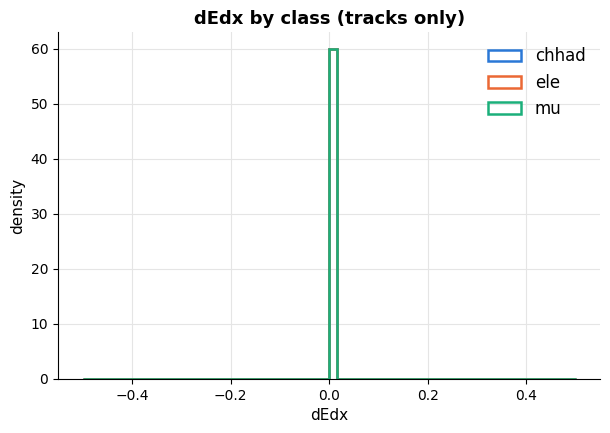

In [13]:
dedx_idx = TRK_FEATURES.index("dEdx")
dedx = X_all[is_track, dedx_idx]

print("dEdx stats: min", dedx.min(), "max", dedx.max(), "mean", dedx.mean(), "zero frac", (dedx == 0).mean())

fig, ax = plt.subplots(figsize=(7, 4.5))
for k in [1, 4, 5]:
    m = is_track & (cls_all == k)
    vals = X_all[m, dedx_idx]
    vals = vals[np.isfinite(vals)]
    ax.hist(vals, bins=60, histtype="step", density=True,
            linewidth=1.8, color=CLASS_COLORS[k], label=CLASS_NAMES[k])
ax.set_xlabel("dEdx")
ax.set_ylabel("density")
ax.legend(frameon=False)
ax.set_title("dEdx by class (tracks only)")
plt.show()

In [3]:
import awkward as ak
import pyarrow.parquet as pq
import numpy as np

t = pq.read_table("/Users/tanya/Downloads/ttbar_reco.parquet")
t = t.replace_schema_metadata({})
arr = ak.from_arrow(t)

print(ak.fields(arr))

['X_track', 'X_cluster', 'ytarget_track', 'ytarget_cluster', 'ycand_track', 'ycand_cluster', 'genmet', 'genjet', 'targetjet']


In [26]:
cl = arr["X_cluster"]
while cl.ndim > 2:                      # collapse rows/events -> (n_clusters, 17)
    cl = ak.flatten(cl, axis=1)

print("n clusters:", len(cl))
for name in ["energy_ecal", "energy_hcal", "energy_other"]:
    v = ak.to_numpy(cl[:, CL_FEATURES.index(name)])
    print(f"{name:13s} min={v.min():.4g} max={v.max():.4g} "
          f"mean={v.mean():.4g} zero_frac={(v == 0).mean():.3f}")

n = len(cl)
for name in ["energy_ecal", "energy_hcal", "energy_other"]:
    v = ak.to_numpy(cl[:, CL_FEATURES.index(name)])
    print(f"clusters with {name} > 0: {(v > 0).sum():,} / {n:,}")

n clusters: 21013676
energy_ecal   min=0 max=0 mean=0 zero_frac=1.000
energy_hcal   min=0 max=0 mean=0 zero_frac=1.000
energy_other  min=0.0002434 max=4975 mean=25.92 zero_frac=0.000
clusters with energy_ecal > 0: 0 / 21,013,676
clusters with energy_hcal > 0: 0 / 21,013,676
clusters with energy_other > 0: 21,013,676 / 21,013,676


In [18]:
# Cell 10: FIXED - Handle variable track lengths safely
x_track_row0 = arr["X_track"][0]  # first row (10 events)
print("num events in this row:", len(x_track_row0))

# Check actual track lengths first
track_lengths = set()
for iev in range(len(x_track_row0)):
    for track in x_track_row0[iev]:
        track_lengths.add(len(track))
print("track lengths seen:", track_lengths)

# Safely access columns
for i in range(min(5, len(x_track_row0[0]))):
    track = x_track_row0[0][i]
    n = len(track)
    dedx_val = track[8] if n > 8 else "N/A"
    dedxerr_val = track[9] if n > 9 else "N/A"
    time_val = track[15] if n > 15 else "N/A"
    print(f"track {i}: dEdx(col8)={dedx_val}, dEdxError(col9)={dedxerr_val}, time(col15)={time_val}")

num events in this row: 10
track lengths seen: {16}
track 0: dEdx(col8)=0.0, dEdxError(col9)=0.0, time(col15)=-1.0
track 1: dEdx(col8)=0.0, dEdxError(col9)=0.0, time(col15)=-1.0
track 2: dEdx(col8)=0.0, dEdxError(col9)=0.0, time(col15)=-1.0
track 3: dEdx(col8)=0.0, dEdxError(col9)=0.0, time(col15)=-1.0
track 4: dEdx(col8)=0.0, dEdxError(col9)=0.0, time(col15)=-1.0


In [19]:
track0 = arr["X_track"][0][0][0]  # row 0, event 0, track 0
print("raw track length:", len(track0))
print("raw track values:", list(track0))

raw track length: 16
raw track values: [np.float64(1.0), np.float64(1.1581823825836182), np.float64(1.6723086833953857), np.float64(-0.4615870714187622), np.float64(-0.8870949149131775), np.float64(3.19210147857666), np.float64(8801.0927734375), np.float64(3.0), np.float64(0.0), np.float64(0.0), np.float64(28.703888377845473), np.float64(2.568317174911499), np.float64(-1.1161264181137085), np.float64(-0.0012951329117640853), np.float64(6.9058380126953125), np.float64(-1.0)]


In [20]:
lengths = set()
for iev in range(10):
    for track in arr["X_track"][0][iev]:
        lengths.add(len(track))
print("unique raw track lengths seen:", lengths)

unique raw track lengths seen: {16}


In [21]:
# Cell 14: Cluster class counts - FIXED to show that only none/nhad/gamma exist
cluster_cls_counts = np.bincount(cls_all[is_cluster], minlength=6)
for k in range(6):
    print(f"{CLASS_NAMES[k]:10s} {cluster_cls_counts[k]}")

none       878875
chhad      0
nhad       625120
gamma      585896
ele        0
mu         0


In [22]:
for name in ["pt", "p", "chi2"]:
    i = TRK_FEATURES.index(name)
    v = X_all[is_track, i]
    print(name, np.percentile(v, [50, 90, 99, 99.9, 99.99]))

pt [2.23428369e+00 2.23769054e+01 2.05717839e+02 1.89856978e+03
 1.79761877e+04]
p [3.62951684e+00 3.27461662e+01 2.98792941e+02 2.84310254e+03
 3.37355669e+04]
chi2 [6.87294336e+03 4.20161688e+05 8.09569755e+06 5.05786106e+07
 1.52976911e+08]


In [23]:
for name in ["energy_ecal", "energy_hcal"]:
    i = CL_FEATURES.index(name)
    v = X_all[is_cluster, i]
    print(name, "min", v.min(), "max", v.max(), "zero_frac", (v==0).mean())
print("energy_other stats:")
vals = X_all[is_cluster, CL_FEATURES.index("energy_other")]
print("min", vals.min(), "max", vals.max(), "mean", vals.mean(), "zero_frac", (vals==0).mean())
e = X_all[is_cluster, CL_FEATURES.index("energy")]
o = X_all[is_cluster, CL_FEATURES.index("energy_other")]
print(np.allclose(e, o), np.abs(e - o).max())

energy_ecal min 0.0 max 0.0 zero_frac 1.0
energy_hcal min 0.0 max 0.0 zero_frac 1.0
energy_other stats:
min 0.00037026306 max 4932.4746 mean 26.08211 zero_frac 0.0
False 963.93555


In [24]:
r = o / e
print("ratio percentiles (1, 50, 99):", np.percentile(r, [1, 50, 99]))
print("fraction equal:", np.isclose(e, o).mean())

ratio percentiles (1, 50, 99): [0.63199195 0.80499959 1.44697039]
fraction equal: 4.784938544641802e-06


In [5]:
import awkward as ak
import pyarrow.parquet as pq
import numpy as np

t = pq.read_table("/Users/tanya/Downloads/ttbar_reco.9600events.parquet")
t = t.replace_schema_metadata({})
arr = ak.from_arrow(t)

print(ak.fields(arr))

['X_track', 'X_cluster', 'ytarget_track', 'ytarget_cluster', 'ycand_track', 'ycand_cluster', 'genmet', 'genjet', 'targetjet']


In [7]:
cl = arr["X_cluster"]
while cl.ndim > 2:                      # collapse rows/events -> (n_clusters, 17)
    cl = ak.flatten(cl, axis=1)

print("n clusters:", len(cl))
for name in ["energy_ecal", "energy_hcal", "energy_other"]:
    v = ak.to_numpy(cl[:, CL_FEATURES.index(name)])
    print(f"{name:13s} min={v.min():.4g} max={v.max():.4g} "
          f"mean={v.mean():.4g} zero_frac={(v == 0).mean():.3f}")

n = len(cl)
for name in ["energy_ecal", "energy_hcal", "energy_other"]:
    v = ak.to_numpy(cl[:, CL_FEATURES.index(name)])
    print(f"clusters with {name} > 0: {(v > 0).sum():,} / {n:,}")

n clusters: 3032460
energy_ecal   min=0 max=4949 mean=13 zero_frac=0.057
energy_hcal   min=0 max=2246 mean=6.203 zero_frac=0.703
energy_other  min=0 max=0.6193 mean=1.118e-05 zero_frac=0.996
clusters with energy_ecal > 0: 2,861,077 / 3,032,460
clusters with energy_hcal > 0: 901,722 / 3,032,460
clusters with energy_other > 0: 13,043 / 3,032,460


cluster feature width: old 100k = 17, new 9600 = 19

idx feature         zero_frac       mean        max
  0 elemtype            0.000          2          2
  1 et                  0.001      15.29       5057
  2 eta                 0.014  -0.001017      8.664
  3 sin_phi             0.004   0.001544          1
  4 cos_phi             0.000  0.0007956          1
  5 energy              0.000      21.33       5735
  6 position.x          0.000      1.726       4100
  7 position.y          0.000      4.824       4088
  8 position.z          0.000     -3.288       4553
  9 iTheta              0.001      1.572      3.142
 10 energy_ecal         0.057         13       4949
 11 energy_hcal         0.703      6.203       2246
 12 energy_other        0.996  1.118e-05     0.6193
 13 num_hits            0.000      237.3  3.048e+04
 14 sigma_x             0.011      38.36       1006
 15 sigma_y             0.011      38.47      911.3
 16 sigma_z             0.013      47.33       1009
 17 num_muo

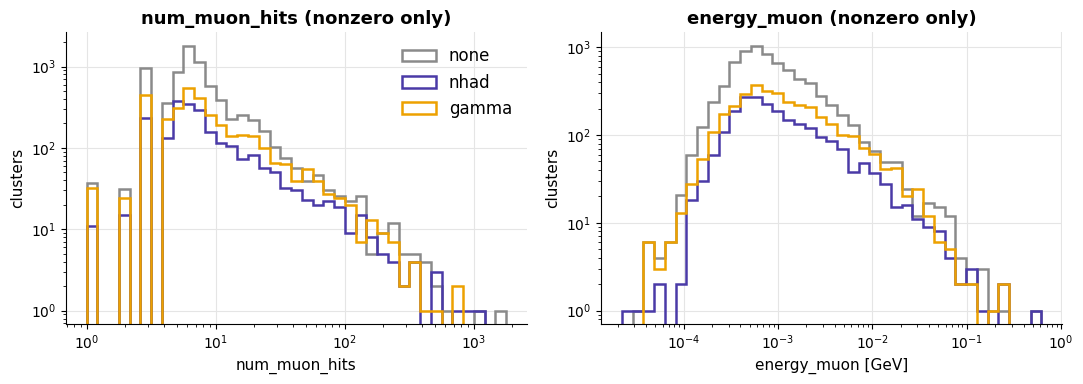

In [8]:
# New cluster features: num_muon_hits and energy_muon (columns 17, 18)
# uses `cl` (new 9600-event clusters, flattened) and `arr` from the two cells above.
# CL_FEATURES stays at 17 names because the npz-based cells above still use the old data.
import pyarrow as pa

CL_FEATURES_NEW = CL_FEATURES + ["num_muon_hits", "energy_muon"]

old_batch = next(pq.ParquetFile("/Users/tanya/Downloads/ttbar_reco.parquet").iter_batches(batch_size=1))
old_cl = ak.from_arrow(pa.Table.from_batches([old_batch]).replace_schema_metadata({}))["X_cluster"]
while old_cl.ndim > 2:
    old_cl = ak.flatten(old_cl, axis=1)
print(f"cluster feature width: old 100k = {len(old_cl[0])}, new 9600 = {len(cl[0])}\n")

print(f"{'idx':>3s} {'feature':15s} {'zero_frac':>9s} {'mean':>10s} {'max':>10s}")
for i, name in enumerate(CL_FEATURES_NEW):
    v = ak.to_numpy(cl[:, i])
    tag = "  <-- new" if i >= len(CL_FEATURES) else ""
    print(f"{i:3d} {name:15s} {(v == 0).mean():9.3f} {v.mean():10.4g} {v.max():10.4g}{tag}")

nmu = ak.to_numpy(cl[:, CL_FEATURES_NEW.index("num_muon_hits")])
emu = ak.to_numpy(cl[:, CL_FEATURES_NEW.index("energy_muon")])
eother = ak.to_numpy(cl[:, CL_FEATURES_NEW.index("energy_other")])
has_mu = nmu > 0
print(f"\nclusters with muon hits: {has_mu.sum():,} / {len(nmu):,} ({100 * has_mu.mean():.2f}%)")
print("num_muon_hits > 0 always means energy_muon > 0:", np.array_equal(has_mu, emu > 0))
print("energy_muon identical to energy_other:", np.array_equal(emu, eother))

# ytarget_cluster column 0 is the raw PDG id (0 = none, 22 = photon, 130 = neutral hadron)
yt = arr["ytarget_cluster"]
while yt.ndim > 2:
    yt = ak.flatten(yt, axis=1)
pdg = ak.to_numpy(yt[:, 0]).astype(int)
for p, name in [(0, "none"), (22, "gamma"), (130, "nhad")]:
    sel = pdg == p
    print(f"  target {name:6s}: {has_mu[sel].sum():6,} of {sel.sum():9,} clusters have muon hits")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, v, name, unit in [(axes[0], nmu, "num_muon_hits", ""), (axes[1], emu, "energy_muon", "GeV")]:
    for p, cname, k in [(0, "none", 0), (130, "nhad", 2), (22, "gamma", 3)]:
        vals = v[has_mu & (pdg == p)]
        if len(vals):
            ax.hist(vals, bins=np.geomspace(v[has_mu].min(), v[has_mu].max(), 40), histtype="step",
                    linewidth=1.8, color=CLASS_COLORS[k], label=cname)
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlabel(f"{name} [{unit}]" if unit else name)
    ax.set_ylabel("clusters")
    ax.set_title(f"{name} (nonzero only)")
axes[0].legend(frameon=False)
fig.tight_layout()
plt.show()

In [15]:
# Match each chhad / electron / muon track to the cluster it points to (needed because those targets only exist
# on tracks, and the parquet has no track-cluster link). Each track is extrapolated as a helix to every cluster's
# radius and matched to the nearest cluster in dR. Reliable above ~5 GeV, so lower-pT tracks are left out.
# uses `arr` (new 9600-event parquet) from the loading cell. Makes: sel_cls, matched, sel_icl, clu, fractions.
MATCH_DR = 0.05
MIN_TRACK_PT = 5.0
TRK_CLASSES = {211: 1, 11: 4, 13: 5}   # target PDG -> class index


def per_event(key, width):
    ev = ak.flatten(arr[key], axis=1)                       # rows x 10 events -> events
    counts = ak.to_numpy(ak.num(ev, axis=1))
    flat = np.asarray(ak.to_numpy(ak.flatten(ev, axis=1))).reshape(-1, width)
    return flat, np.concatenate([[0], np.cumsum(counts)])


trk, trk_off = per_event("X_track", 16)
clu, clu_off = per_event("X_cluster", 19)
ytrk, _ = per_event("ytarget_track", 14)

sel_cls, sel_p, sel_dr, sel_icl = [], [], [], []
for iev in range(len(trk_off) - 1):
    t = trk[trk_off[iev]:trk_off[iev + 1]]
    c = clu[clu_off[iev]:clu_off[iev + 1]]
    pdg = ytrk[trk_off[iev]:trk_off[iev + 1], 0].astype(int)
    keep = np.isin(pdg, list(TRK_CLASSES)) & (t[:, 1] >= MIN_TRACK_PT)
    if not keep.any() or len(c) == 0:
        continue
    t, pdg = t[keep], pdg[keep]
    phi0, tanl, omega, z0 = np.arctan2(t[:, 3], t[:, 4])[:, None], t[:, 11][:, None], t[:, 13][:, None], t[:, 14][:, None]
    r = np.hypot(c[:, 6], c[:, 7])[None, :]
    half_turn = np.clip(r * np.abs(omega) / 2, 0, 1)
    arc = np.where(np.abs(omega) > 1e-12, 2 * np.arcsin(half_turn) / np.maximum(np.abs(omega), 1e-12), r)
    dphi = np.angle(np.exp(1j * (np.arctan2(c[:, 7], c[:, 6])[None, :] - (phi0 - np.sign(omega) * np.arcsin(half_turn)))))
    deta = np.arcsinh(c[:, 8][None, :] / r) - np.arcsinh((z0 + arc * tanl) / r)
    dr = np.where(r * np.abs(omega) / 2 < 1, np.hypot(dphi, deta), 99.0)
    best = dr.argmin(axis=1)
    sel_cls.append(np.array([TRK_CLASSES[p] for p in pdg]))
    sel_p.append(t[:, 5])
    sel_dr.append(dr[np.arange(len(t)), best])
    sel_icl.append(clu_off[iev] + best)

sel_cls, sel_p, sel_dr, sel_icl = map(np.concatenate, (sel_cls, sel_p, sel_dr, sel_icl))
matched = sel_dr < MATCH_DR


def fractions(cl_rows):
    ecal, hcal, other = cl_rows[:, 10], cl_rows[:, 11], cl_rows[:, 12]
    total = ecal + hcal + other
    ok = total > 0
    return ecal[ok] / total[ok], hcal[ok] / total[ok], other[ok] / total[ok]


print(f"Tracks with pT > {MIN_TRACK_PT:g} GeV, matched to nearest cluster within dR < {MATCH_DR}")
print(f"{'target':7s} {'tracks':>8s} {'matched':>8s} {'mean ECAL':>10s} {'mean HCAL':>10s} {'other > 0':>10s} {'median E/p':>11s}")
for k in (1, 5, 4):
    m = (sel_cls == k) & matched
    rows = clu[sel_icl[m]]
    fr = fractions(rows)
    print(f"{CLASS_NAMES[k]:7s} {np.sum(sel_cls == k):8,d} {m.sum() / max(np.sum(sel_cls == k), 1):8.2f} "
          f"{fr[0].mean():10.3f} {fr[1].mean():10.3f} {np.mean(rows[:, 12] > 0):10.3f} {np.median(rows[:, 5] / sel_p[m]):11.2f}")


Tracks with pT > 5 GeV, matched to nearest cluster within dR < 0.05
target    tracks  matched  mean ECAL  mean HCAL  other > 0  median E/p
chhad    469,844     0.98      0.772      0.228      0.018        0.68
mu         5,456     0.97      0.546      0.454      0.315        0.10
ele        7,886     0.99      0.921      0.079      0.013        0.94


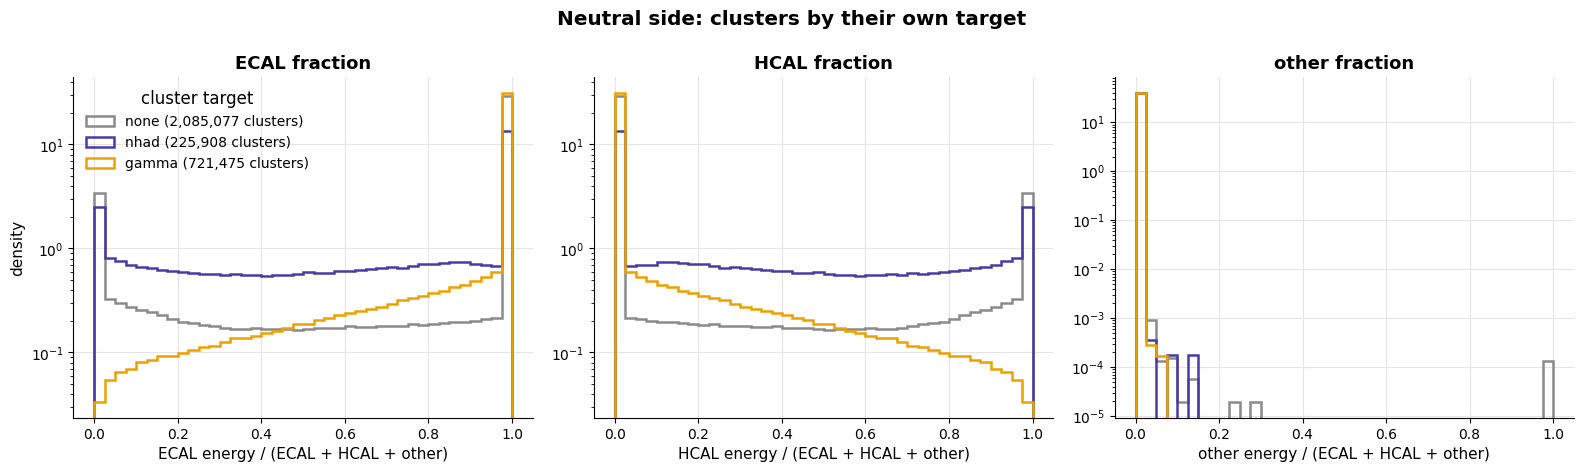

In [13]:
# ECAL, HCAL and other fraction for clusters, by the cluster's own target (none / nhad / gamma).
# uses `arr` (new 9600-event parquet) from the loading cell.
cl_all = arr["X_cluster"]
yt_all = arr["ytarget_cluster"]
while cl_all.ndim > 2:
    cl_all, yt_all = ak.flatten(cl_all, axis=1), ak.flatten(yt_all, axis=1)
cl_all, cl_target = ak.to_numpy(cl_all), ak.to_numpy(yt_all[:, 0]).astype(int)
assert cl_all.shape[1] == 19, "arr is not the 9600-event file: rerun the cell that loads ttbar_reco.9600events.parquet"

total_all = cl_all[:, 10] + cl_all[:, 11] + cl_all[:, 12]
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
for ax, (name, col) in zip(axes, [("ECAL", 10), ("HCAL", 11), ("other", 12)]):
    for pdg_code, k in [(0, 0), (130, 2), (22, 3)]:
        sel = cl_target == pdg_code
        ax.hist(cl_all[sel, col] / total_all[sel], bins=np.linspace(0, 1, 41), histtype="step", density=True,
                linewidth=1.8, color=CLASS_COLORS[k], label=f"{CLASS_NAMES[k]} ({sel.sum():,} clusters)")
    ax.set_yscale("log")
    ax.set_xlabel(f"{name} energy / (ECAL + HCAL + other)")
    ax.set_title(f"{name} fraction")
axes[0].set_ylabel("density")
axes[0].legend(frameon=False, fontsize=10, title="cluster target")
fig.suptitle("Neutral side: clusters by their own target", fontweight="bold")
fig.tight_layout()
plt.show()


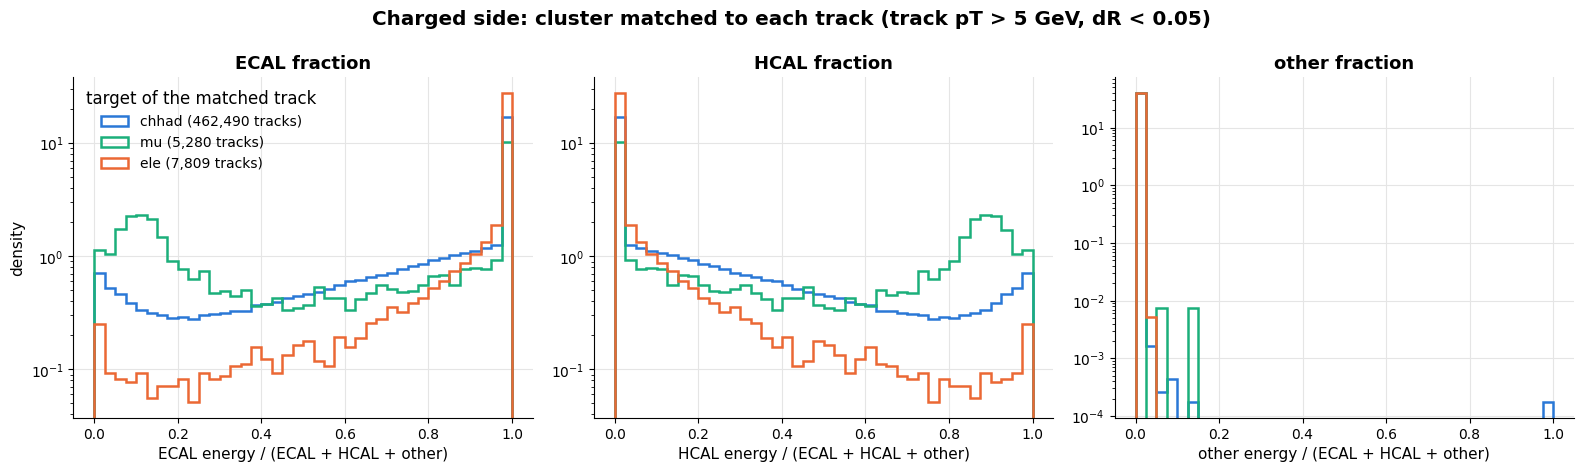

In [14]:
# ECAL, HCAL and other fraction for the cluster each charged particle's track points to (chhad / muon / electron).
# uses the track-cluster matching from the long matching cell (sel_cls, matched, sel_icl, clu, fractions).
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
for k in (1, 5, 4):
    m = (sel_cls == k) & matched
    for ax, f in zip(axes, fractions(clu[sel_icl[m]])):
        ax.hist(f, bins=np.linspace(0, 1, 41), histtype="step", density=True, linewidth=1.8,
                color=CLASS_COLORS[k], label=f"{CLASS_NAMES[k]} ({m.sum():,} tracks)")
for ax, name in zip(axes, ["ECAL", "HCAL", "other"]):
    ax.set_yscale("log")
    ax.set_xlabel(f"{name} energy / (ECAL + HCAL + other)")
    ax.set_title(f"{name} fraction")
axes[0].set_ylabel("density")
axes[0].legend(frameon=False, fontsize=10, title="target of the matched track")
fig.suptitle(f"Charged side: cluster matched to each track (track pT > {MIN_TRACK_PT:g} GeV, dR < {MATCH_DR})", fontweight="bold")
fig.tight_layout()
plt.show()


target   on tracks  on clusters
none       170,394    2,085,077
chhad      824,371            0
nhad             0      225,908
gamma            0      721,475
ele         13,137            0
mu           6,353            0


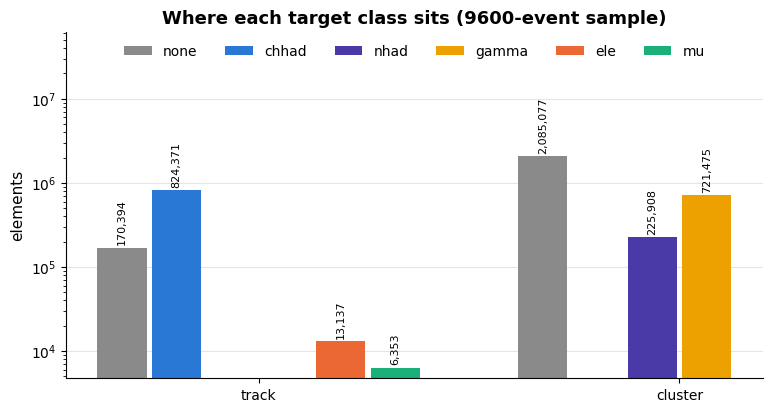

In [8]:
def flat2d(key):
    x = arr[key]
    while x.ndim > 2:
        x = ak.flatten(x, axis=1)
    return ak.to_numpy(x)


trk, clu = flat2d("X_track"), flat2d("X_cluster")
assert clu.shape[1] == 19, "arr is not the 9600-event file: rerun the cell that loads ttbar_reco.9600events.parquet"
PDG_TO_CLASS = {0: 0, 211: 1, 130: 2, 22: 3, 11: 4, 13: 5}
trk_cls = np.array([PDG_TO_CLASS[p] for p in flat2d("ytarget_track")[:, 0].astype(int)])
clu_cls = np.array([PDG_TO_CLASS[p] for p in flat2d("ytarget_cluster")[:, 0].astype(int)])

# 1) where each target class sits: on tracks or on clusters
counts = np.array([[np.sum(trk_cls == k), np.sum(clu_cls == k)] for k in range(6)])
print(f"{'target':7s} {'on tracks':>10s} {'on clusters':>12s}")
for k in range(6):
    print(f"{CLASS_NAMES[k]:7s} {counts[k, 0]:10,d} {counts[k, 1]:12,d}")

fig, ax = plt.subplots(figsize=(9, 4.5))
x, width = np.arange(2), 0.13
for k in range(6):
    xpos, nonzero = x + (k - 2.5) * width, counts[k] > 0
    bars = ax.bar(xpos[nonzero], counts[k][nonzero], width * 0.9, color=CLASS_COLORS[k], label=CLASS_NAMES[k])
    ax.bar_label(bars, labels=[f"{c:,}" for c in counts[k][nonzero]], fontsize=8, padding=2, rotation=90)
ax.set_xticks(x)
ax.set_xticklabels(["track", "cluster"])
ax.set_yscale("log")
ax.set_ylim(top=counts.max() * 30)
ax.set_ylabel("elements")
ax.set_title("Where each target class sits (9600-event sample)")
ax.grid(axis="x", visible=False)
ax.legend(ncol=6, loc="upper center", frameon=False, fontsize=10)
plt.show()


model input: 970 test events, 19 features per element, 296,533 clusters
feature       col  nonzero (model input)  nonzero (parquet)  mean (model input)  mean (parquet)
energy_ecal    10                  0.943              0.943               13.29              13
energy_hcal    11                  0.299              0.297               6.324           6.203
energy_other   12                  0.004              0.004           9.833e-06       1.118e-05
any two of the three columns identical in the model input: False
energy column equal to ecal + hcal + other: False


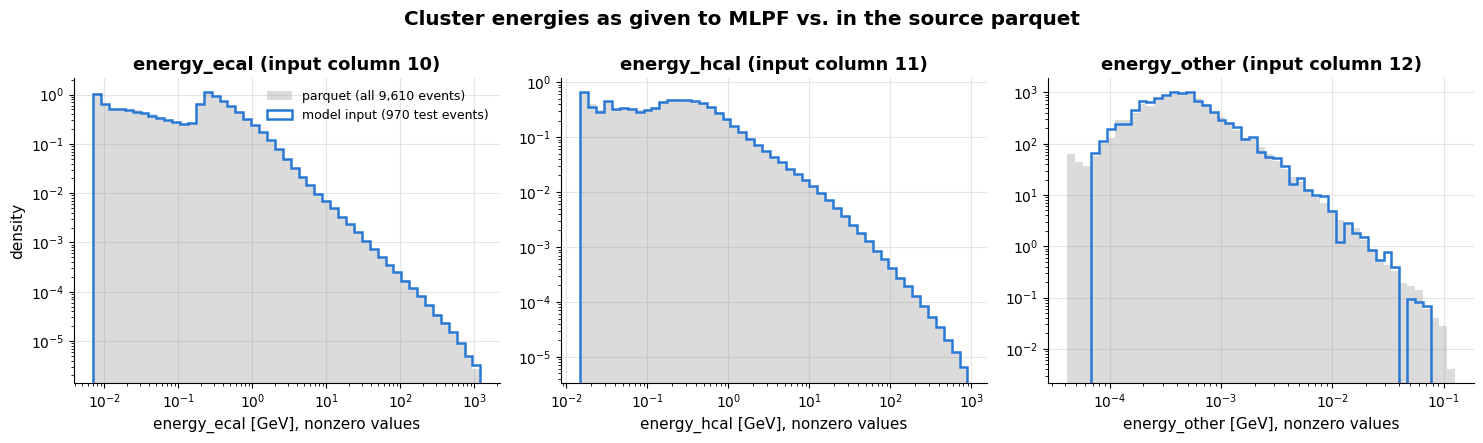

In [9]:
# Do the model's inputs contain ECAL / HCAL / other energy as three separate features?
# The prediction files store the input matrix the model was given at test time ("inputs").
# Compare its cluster columns with the same columns in the parquet the dataset was built from.
import glob, os

PRED_DIR = os.path.expanduser("~/Downloads/attention-9600/preds_step_18200/muoncollider_ttbar_pf")
pred = ak.concatenate([ak.from_parquet(f) for f in sorted(glob.glob(f"{PRED_DIR}/pred_*.parquet"))])
X_model = ak.to_numpy(ak.flatten(pred["inputs"], axis=1))      # (elements, 19): what the model saw
cl_model = X_model[X_model[:, 0] == 2]                          # elemtype 2 = cluster

cl_parquet = arr["X_cluster"]
while cl_parquet.ndim > 2:
    cl_parquet = ak.flatten(cl_parquet, axis=1)
cl_parquet = ak.to_numpy(cl_parquet)
assert cl_parquet.shape[1] == 19, "arr is not the 9600-event file: rerun the cell that loads ttbar_reco.9600events.parquet"

print(f"model input: {len(pred):,} test events, {X_model.shape[1]} features per element, {len(cl_model):,} clusters")
print(f"{'feature':13s} {'col':>3s} {'nonzero (model input)':>22s} {'nonzero (parquet)':>18s} {'mean (model input)':>19s} {'mean (parquet)':>15s}")
cols = [("energy_ecal", 10), ("energy_hcal", 11), ("energy_other", 12)]
for name, i in cols:
    print(f"{name:13s} {i:3d} {np.mean(cl_model[:, i] > 0):22.3f} {np.mean(cl_parquet[:, i] > 0):18.3f} "
          f"{cl_model[:, i].mean():19.4g} {cl_parquet[:, i].mean():15.4g}")
print("any two of the three columns identical in the model input:",
      any(np.array_equal(cl_model[:, a], cl_model[:, b]) for a, b in [(10, 11), (10, 12), (11, 12)]))
print("energy column equal to ecal + hcal + other:", np.allclose(cl_model[:, 5], cl_model[:, 10:13].sum(axis=1)))

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, (name, i) in zip(axes, cols):
    pos = np.concatenate([cl_model[cl_model[:, i] > 0, i], cl_parquet[cl_parquet[:, i] > 0, i]])
    bins = np.geomspace(*np.percentile(pos, [0.1, 99.9]), 50)
    ax.hist(cl_parquet[cl_parquet[:, i] > 0, i], bins=bins, histtype="stepfilled", density=True, alpha=0.3,
            color="#8a8a8a", label="parquet (all 9,610 events)")
    ax.hist(cl_model[cl_model[:, i] > 0, i], bins=bins, histtype="step", density=True, linewidth=1.8,
            color="#2a78d6", label=f"model input ({len(pred):,} test events)")
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlabel(f"{name} [GeV], nonzero values")
    ax.set_title(f"{name} (input column {i})")
axes[0].set_ylabel("density")
axes[0].legend(frameon=False, fontsize=9)
fig.suptitle("Cluster energies as given to MLPF vs. in the source parquet", fontweight="bold")
fig.tight_layout()
plt.show()




ECAL   fraction: mean 0.830, exactly 0 in 5.7% of clusters, exactly 1 in 70.2%
HCAL   fraction: mean 0.170, exactly 0 in 70.3% of clusters, exactly 1 in 5.6%
other  fraction: mean 0.000, exactly 0 in 99.6% of clusters, exactly 1 in 0.0%


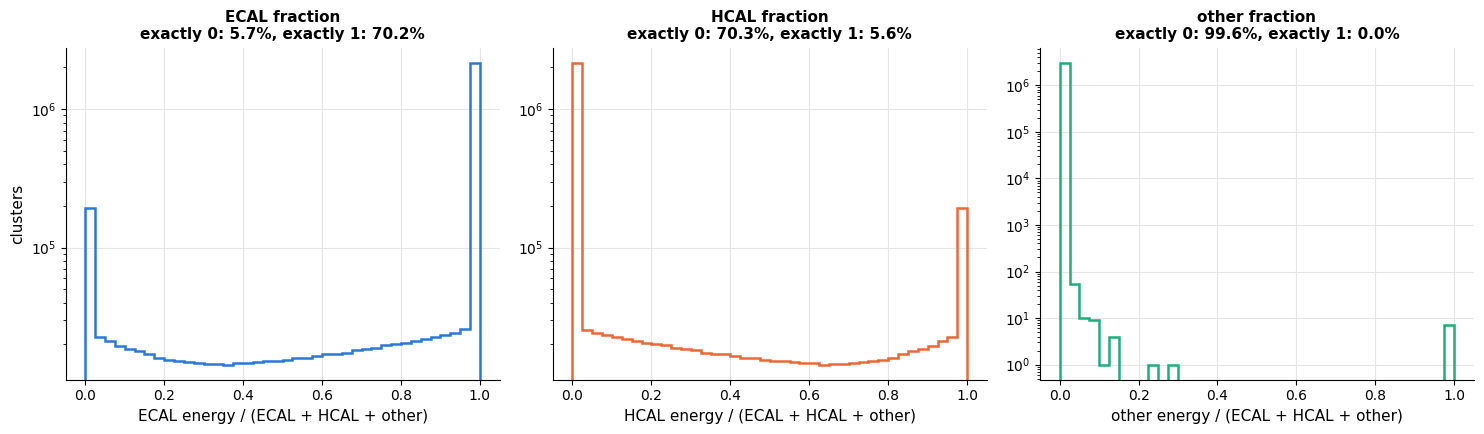

In [19]:
cl = arr["X_cluster"]
while cl.ndim > 2:
    cl = ak.flatten(cl, axis=1)
cl = ak.to_numpy(cl)
assert cl.shape[1] == 19, "arr is not the 9600-event file: rerun the cell that loads ttbar_reco.9600events.parquet"

ecal, hcal, other = cl[:, 10], cl[:, 11], cl[:, 12]
total = ecal + hcal + other

bins = np.linspace(0, 1, 41)
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, (name, energy, color) in zip(axes, [("ECAL", ecal, "#2a78d6"), ("HCAL", hcal, "#eb6834"), ("other", other, "#1baf7a")]):
    frac = energy / total
    ax.hist(frac, bins=bins, histtype="step", linewidth=1.8, color=color)
    ax.set_yscale("log")
    ax.set_xlabel(f"{name} energy / (ECAL + HCAL + other)")
    ax.set_title(f"{name} fraction\nexactly 0: {100 * np.mean(frac == 0):.1f}%, exactly 1: {100 * np.mean(frac == 1):.1f}%", fontsize=11)
    print(f"{name:6s} fraction: mean {frac.mean():.3f}, exactly 0 in {100 * np.mean(frac == 0):.1f}% of clusters, exactly 1 in {100 * np.mean(frac == 1):.1f}%")
axes[0].set_ylabel("clusters")
fig.tight_layout()
plt.show()



In [9]:
# Class imbalance among true particles in the 9600-event sample, and the loss weights it suggests.
# Weights are relative to charged hadrons (the most common class): inverse frequency makes every class
# contribute about equally to the particle-type loss; the square root is a milder version.
# uses `arr` (new 9600-event parquet) from the loading cell above.
PDG_TO_CLASS = {0: 0, 211: 1, 130: 2, 22: 3, 11: 4, 13: 5}
class_counts = np.zeros(6, dtype=int)
for key in ("ytarget_track", "ytarget_cluster"):
    y = arr[key]
    while y.ndim > 2:
        y = ak.flatten(y, axis=1)
    pdg_values, n = np.unique(ak.to_numpy(y[:, 0]).astype(int), return_counts=True)
    for p, c in zip(pdg_values, n):
        class_counts[PDG_TO_CLASS[p]] += c

n_particles = class_counts[1:].sum()
inv_freq = class_counts[1] / class_counts.astype(float)
print(f"{'class':7s} {'count':>10s} {'% of true particles':>20s} {'times rarer than chhad':>23s} {'sqrt':>6s}")
for k in range(1, 6):
    print(f"{CLASS_NAMES[k]:7s} {class_counts[k]:10,d} {100 * class_counts[k] / n_particles:19.2f}% {inv_freq[k]:23.1f} {np.sqrt(inv_freq[k]):6.1f}")
print(f"(none: {class_counts[0]:,} elements, not counted as particles)")

# in the order FocalLoss(alpha=...) expects: none, chhad, nhad, gamma, ele, mu (the none weight is never used)
print("\ninverse-frequency alpha:", [1.0] + [round(float(w), 1) for w in inv_freq[1:]])
print("square-root alpha:      ", [1.0] + [round(float(np.sqrt(w)), 1) for w in inv_freq[1:]])

class        count  % of true particles  times rarer than chhad   sqrt
chhad      824,371               46.02%                     1.0    1.0
nhad       225,908               12.61%                     3.6    1.9
gamma      721,475               40.28%                     1.1    1.1
ele         13,137                0.73%                    62.8    7.9
mu           6,353                0.35%                   129.8   11.4
(none: 2,255,471 elements, not counted as particles)

inverse-frequency alpha: [1.0, 1.0, 3.6, 1.1, 62.8, 129.8]
square-root alpha:       [1.0, 1.0, 1.9, 1.1, 7.9, 11.4]


9,610 events with calorimeter energy (of 9,610)
whole sample: ECAL 0.677, HCAL 0.323, other 5.82e-07


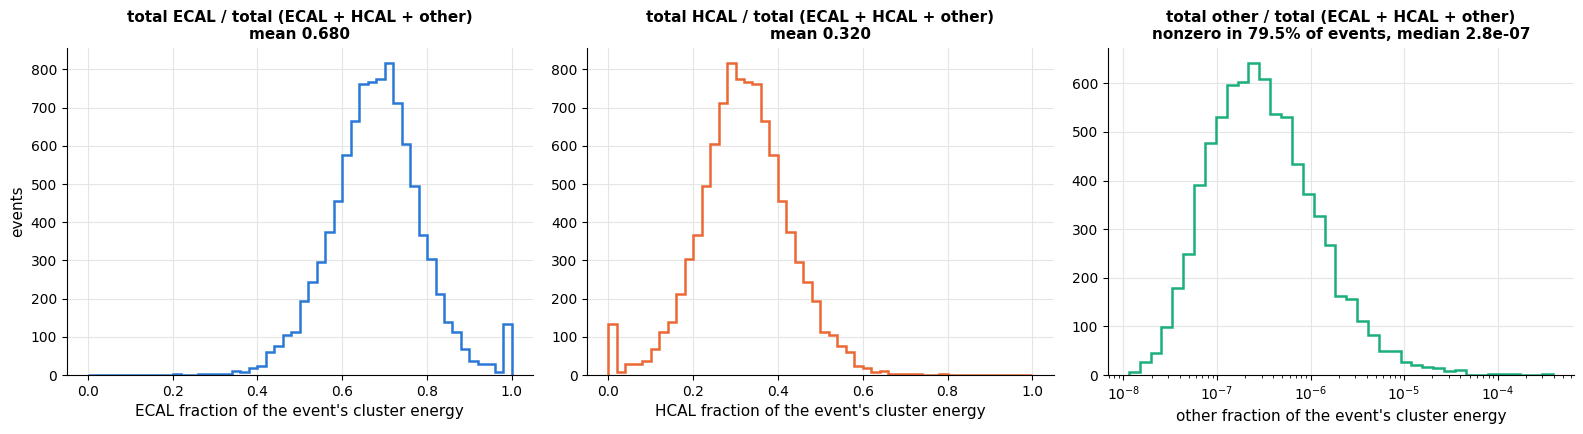

In [17]:
# Per-event energy fractions: for each event, add up the ECAL, HCAL and other energy of all its clusters,
# then divide each sum by the event's total (ECAL + HCAL + other). One entry per event.
# uses `arr` (new 9600-event parquet) from the loading cell.
ev_clusters = ak.flatten(arr["X_cluster"], axis=1)             # rows x 10 events -> events x clusters x 19
assert len(ev_clusters[0][0]) == 19, "arr is not the 9600-event file: rerun the cell that loads ttbar_reco.9600events.parquet"
ev_ecal = ak.to_numpy(ak.sum(ev_clusters[:, :, 10], axis=1))
ev_hcal = ak.to_numpy(ak.sum(ev_clusters[:, :, 11], axis=1))
ev_other = ak.to_numpy(ak.sum(ev_clusters[:, :, 12], axis=1))
ev_total = ev_ecal + ev_hcal + ev_other
has_energy = ev_total > 0

print(f"{has_energy.sum():,} events with calorimeter energy (of {len(ev_total):,})")
print(f"whole sample: ECAL {ev_ecal.sum() / ev_total.sum():.3f}, HCAL {ev_hcal.sum() / ev_total.sum():.3f}, other {ev_other.sum() / ev_total.sum():.2e}")

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, (name, v, color) in zip(axes, [("ECAL", ev_ecal, "#2a78d6"), ("HCAL", ev_hcal, "#eb6834"), ("other", ev_other, "#1baf7a")]):
    frac = v[has_energy] / ev_total[has_energy]
    if name == "other":      # tiny values: log-spaced bins over the nonzero ones
        nonzero = frac[frac > 0]
        ax.hist(nonzero, bins=np.geomspace(nonzero.min(), nonzero.max(), 40), histtype="step", linewidth=1.8, color=color)
        ax.set_xscale("log")
        ax.set_title(f"total other / total (ECAL + HCAL + other)\nnonzero in {100 * len(nonzero) / len(frac):.1f}% of events, median {np.median(nonzero):.1e}", fontsize=11)
    else:
        ax.hist(frac, bins=np.linspace(0, 1, 51), histtype="step", linewidth=1.8, color=color)
        ax.set_title(f"total {name} / total (ECAL + HCAL + other)\nmean {frac.mean():.3f}", fontsize=11)
    ax.set_xlabel(f"{name} fraction of the event's cluster energy")
axes[0].set_ylabel("events")
fig.tight_layout()
plt.show()


3,032,460 clusters, total energy 58,232,715 GeV
total ECAL  =  39,423,089.15 GeV   ->   total ECAL / total (ECAL + HCAL + other) = 0.677
total HCAL  =  18,809,591.76 GeV   ->   total HCAL / total (ECAL + HCAL + other) = 0.323
total other =          33.91 GeV   ->   total other / total (ECAL + HCAL + other) = 5.82e-07


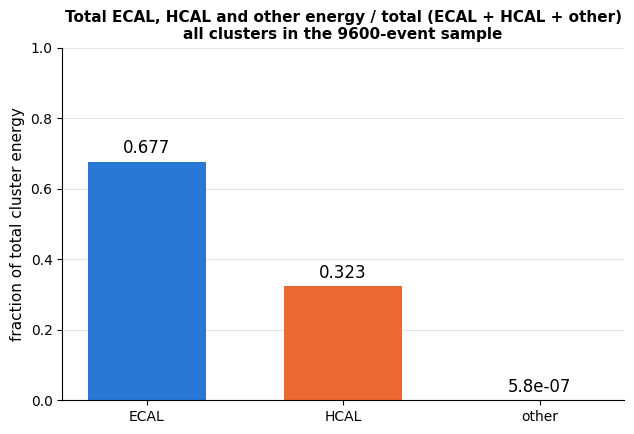

In [18]:
# Whole-sample energy fractions: add up ECAL, HCAL and other energy over every cluster in the sample,
# then divide each sum by the grand total (ECAL + HCAL + other). One number each.
# uses `arr` (new 9600-event parquet) from the loading cell.
cl_sum = arr["X_cluster"]
while cl_sum.ndim > 2:
    cl_sum = ak.flatten(cl_sum, axis=1)
cl_sum = ak.to_numpy(cl_sum)
assert cl_sum.shape[1] == 19, "arr is not the 9600-event file: rerun the cell that loads ttbar_reco.9600events.parquet"

sum_ecal, sum_hcal, sum_other = cl_sum[:, 10].sum(), cl_sum[:, 11].sum(), cl_sum[:, 12].sum()
sum_total = sum_ecal + sum_hcal + sum_other
names = ["ECAL", "HCAL", "other"]
sums = np.array([sum_ecal, sum_hcal, sum_other])
fracs = sums / sum_total

print(f"{len(cl_sum):,} clusters, total energy {sum_total:,.0f} GeV")
for name, s, f in zip(names, sums, fracs):
    print(f"total {name:5s} = {s:14,.2f} GeV   ->   total {name} / total (ECAL + HCAL + other) = {f:.3g}")

fig, ax = plt.subplots(figsize=(6.5, 4.5))
bars = ax.bar(names, fracs, color=["#2a78d6", "#eb6834", "#1baf7a"], width=0.6)
ax.bar_label(bars, labels=[f"{f:.3f}" if f > 1e-3 else f"{f:.1e}" for f in fracs], padding=3)
ax.set_ylim(0, 1)
ax.set_ylabel("fraction of total cluster energy")
ax.set_title("Total ECAL, HCAL and other energy / total (ECAL + HCAL + other)\nall clusters in the 9600-event sample", fontsize=11)
ax.grid(axis="x", visible=False)
fig.tight_layout()
plt.show()
